<center><h1>Zhao_Yibo_HW4</h1></center>
<br>
<br>

Name: Zhao Yibo
<br>
Github Username: Artmu-bo
<br>
USC ID: 5635641435

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os, glob, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, auc, accuracy_score)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
warnings.filterwarnings('ignore')

Get the AReM Data Set

In [2]:
DATA_DIR = '../data/AReM'
COLS = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

records = []
for activity in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, activity)
    if not os.path.isdir(folder):
        continue
    for path in glob.glob(os.path.join(folder, 'dataset*.csv')):
        num = int(re.search(r'dataset(\d+)\.csv', path).group(1))
        df = pd.read_csv(path, comment='#', header=None, sep=r'[,\s]+',
                         engine='python', usecols=range(7))
        df.columns = ['time'] + COLS
        records.append({'activity': activity, 'dataset': num, 'data': df})

records.sort(key=lambda r: (r['activity'], r['dataset']))
print('Total instances:', len(records))
print(pd.Series([r['activity'] for r in records]).value_counts().sort_index())

Total instances: 88
bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15
Name: count, dtype: int64


**NOTE**<br>
The dataset has 88 instances in 7 activity folders (bending1: 7, bending2: 6, the other five: 15 each).
Each instance contains 6 time series of 480 values. Minor cleaning is handled during parsing:
- `bending2/dataset4.csv` is space-separated → `sep=r'[,\s]+'` accepts commas or whitespace.
- `cycling/dataset9.csv` and `dataset14.csv` have a trailing comma → `usecols=range(7)` drops the empty column.
- `sitting/dataset8.csv` has 479 rows instead of 480 → kept as is (segments are split approximately equally).

### (b) Splitting Data

In [3]:
# Test set: datasets 1-2 of bending1/bending2 and datasets 1-3 of other activities
def is_test(r):
    if r['activity'] in ('bending1', 'bending2'):
        return r['dataset'] in (1, 2)
    return r['dataset'] in (1, 2, 3)

train_records = [r for r in records if not is_test(r)]
test_records = [r for r in records if is_test(r)]
print('Train:', len(train_records), '| Test:', len(test_records))

Train: 69 | Test: 19


### (c) Feature Extraction

In [4]:
# Extract 7 time-domain features from each of l (approximately) equal segments of the 6 series
def extract_features(df, l=1):
    feats = {}
    for i, col in enumerate(COLS, start=1):
        for j, seg in enumerate(np.array_split(df[col].to_numpy(), l), start=1):
            s = pd.Series(seg)
            sfx = f'{i}' if l == 1 else f'{i}_part{j}'
            feats[f'min{sfx}'] = s.min()
            feats[f'max{sfx}'] = s.max()
            feats[f'mean{sfx}'] = s.mean()
            feats[f'median{sfx}'] = s.median()
            feats[f'std{sfx}'] = s.std()
            feats[f'1st_quart{sfx}'] = s.quantile(0.25)
            feats[f'3rd_quart{sfx}'] = s.quantile(0.75)
    return feats

# Build feature matrix, binary label (1 = bending) and activity label for a set of instances
def build_dataset(recs, l=1):
    X = pd.DataFrame([extract_features(r['data'], l) for r in recs])
    activity = pd.Series([r['activity'] for r in recs], name='activity')
    y_bin = activity.str.startswith('bending').astype(int).rename('bending')
    return X, y_bin, activity

X_train1, y_train, act_train = build_dataset(train_records, l=1)
X_test1, y_test, act_test = build_dataset(test_records, l=1)
print('Train features:', X_train1.shape, '| Test features:', X_test1.shape)
X_train1.head()

Train features: (69, 42) | Test features: (19, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
2,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
3,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
4,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83


**NOTE**<br>
（1）With l = 1, each instance has 6 series × 7 features = 42 features (69 × 42 for training, 19 × 42 for test).
Column names follow `<feature><series>` (e.g. `mean1`); for l > 1 they become `<feature><series>_part<j>`.<br>
（2）Following Homework 3 1(c)iv, the three selected features are **mean, 3rd quartile and standard deviation**.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

bending
other      60
bending     9
Name: count, dtype: int64


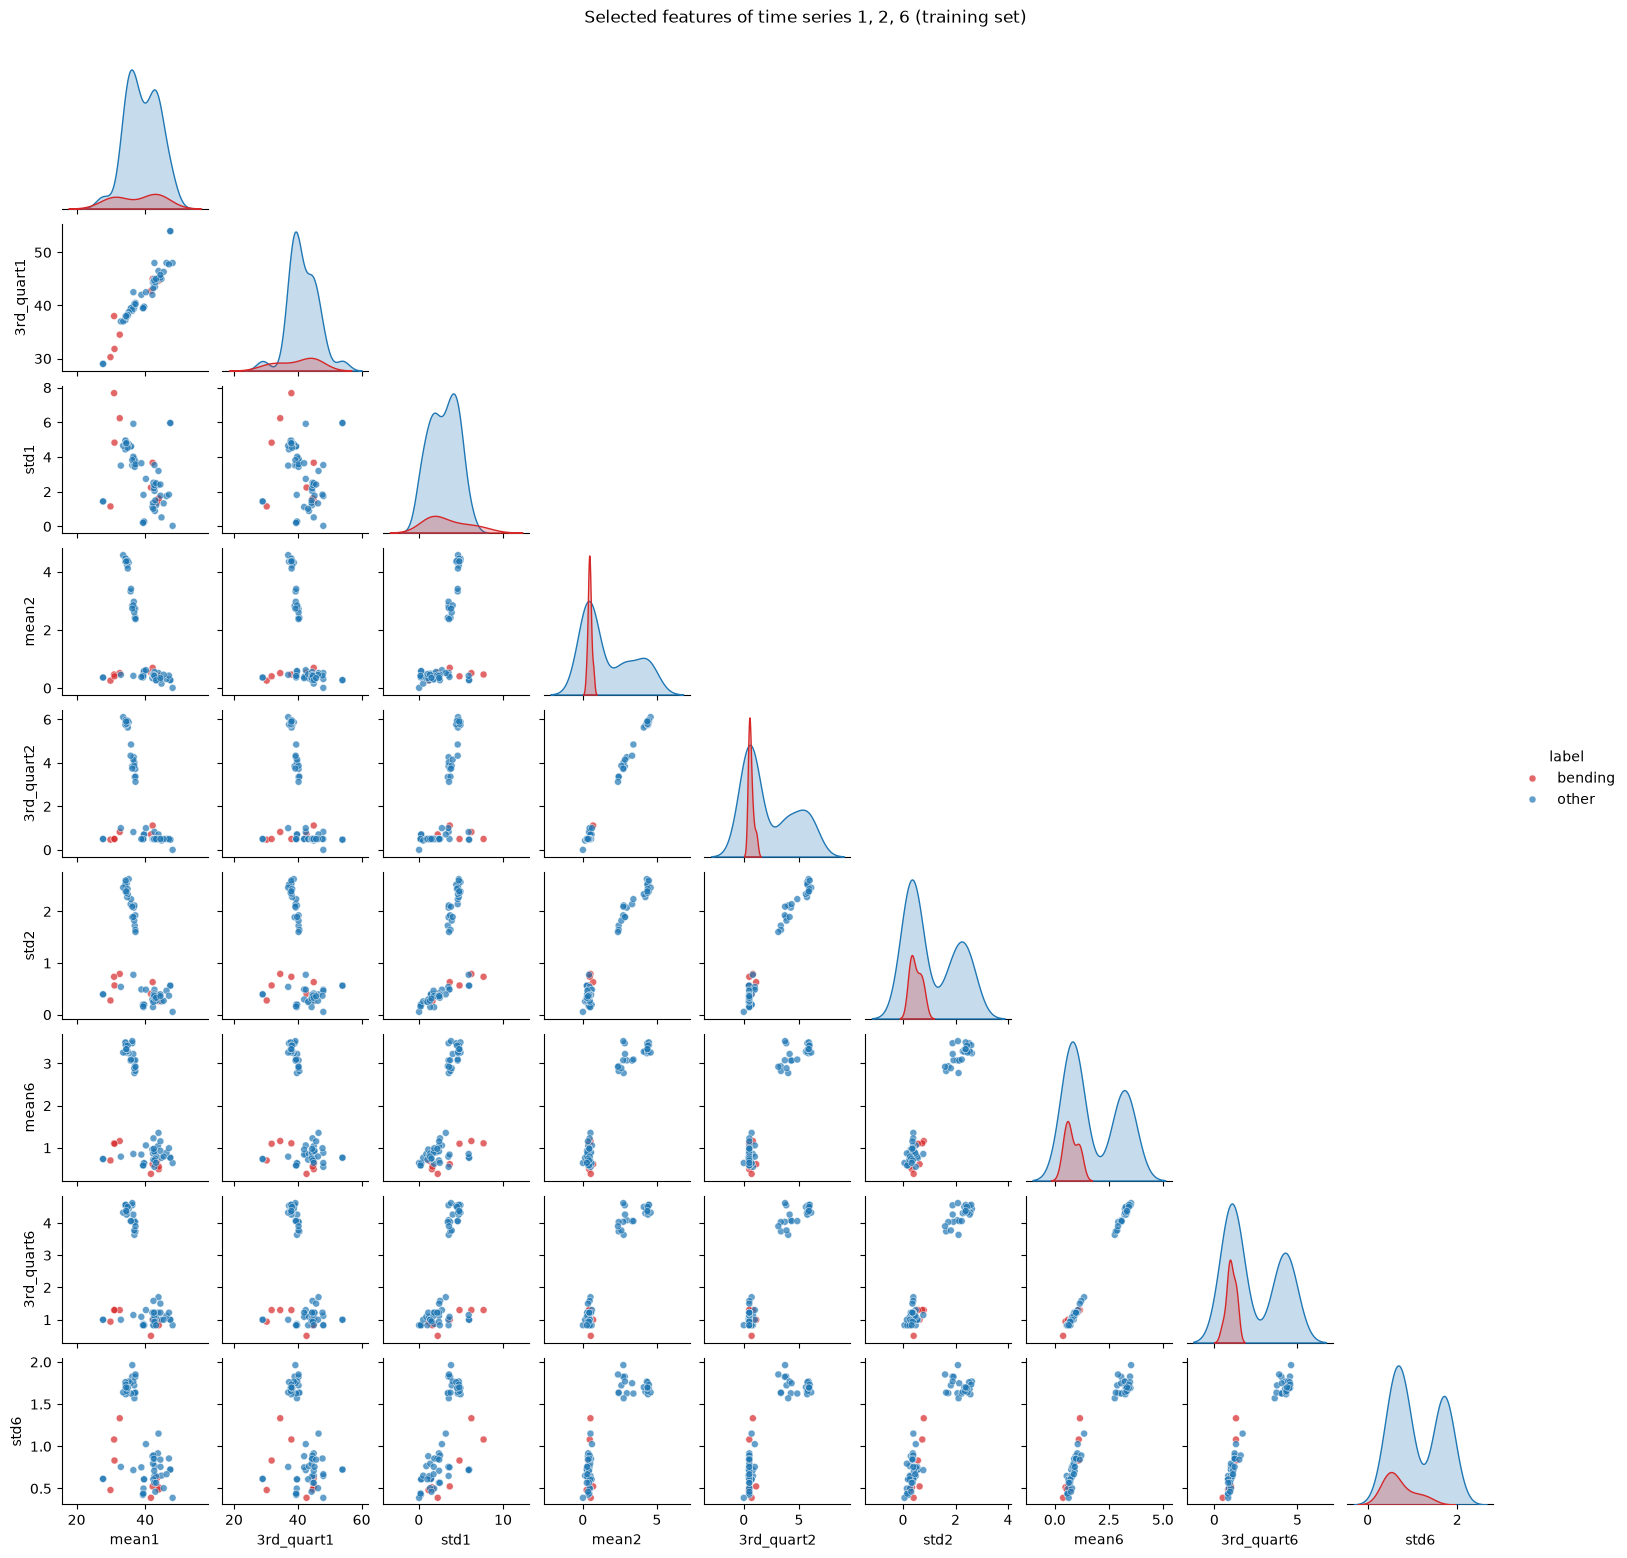

In [5]:
# Pair plot of mean, 3rd quartile and std from series 1, 2, 6 (training set), bending vs. other
print(y_train.map({1: 'bending', 0: 'other'}).value_counts())

sel = [f'{stat}{i}' for i in (1, 2, 6) for stat in ('mean', '3rd_quart', 'std')]
plot_df = X_train1[sel].assign(label=y_train.map({1: 'bending', 0: 'other'}))
g = sns.pairplot(plot_df, hue='label', palette={'bending': 'tab:red', 'other': 'tab:blue'},
                 corner=True, diag_kind='kde', height=1.7,
                 plot_kws={'s': 25, 'alpha': 0.7})
g.figure.suptitle('Selected features of time series 1, 2, 6 (training set)', y=1.02)
plt.show()

**NOTE**<br>
9 bending vs. 60 other training instances (red = bending, blue = other; diagonal = class-wise density).

- Bending is clearly separated from the **dynamic activities**, which have high values in the variance series (2 and 6).
- It overlaps with the **static activities** in most panels; no single feature separates the classes.
- Mean and 3rd quartile of the same series are almost perfectly correlated, so they are largely redundant.

#### ii. Splitted Plots

Train features with l=2: (69, 84)


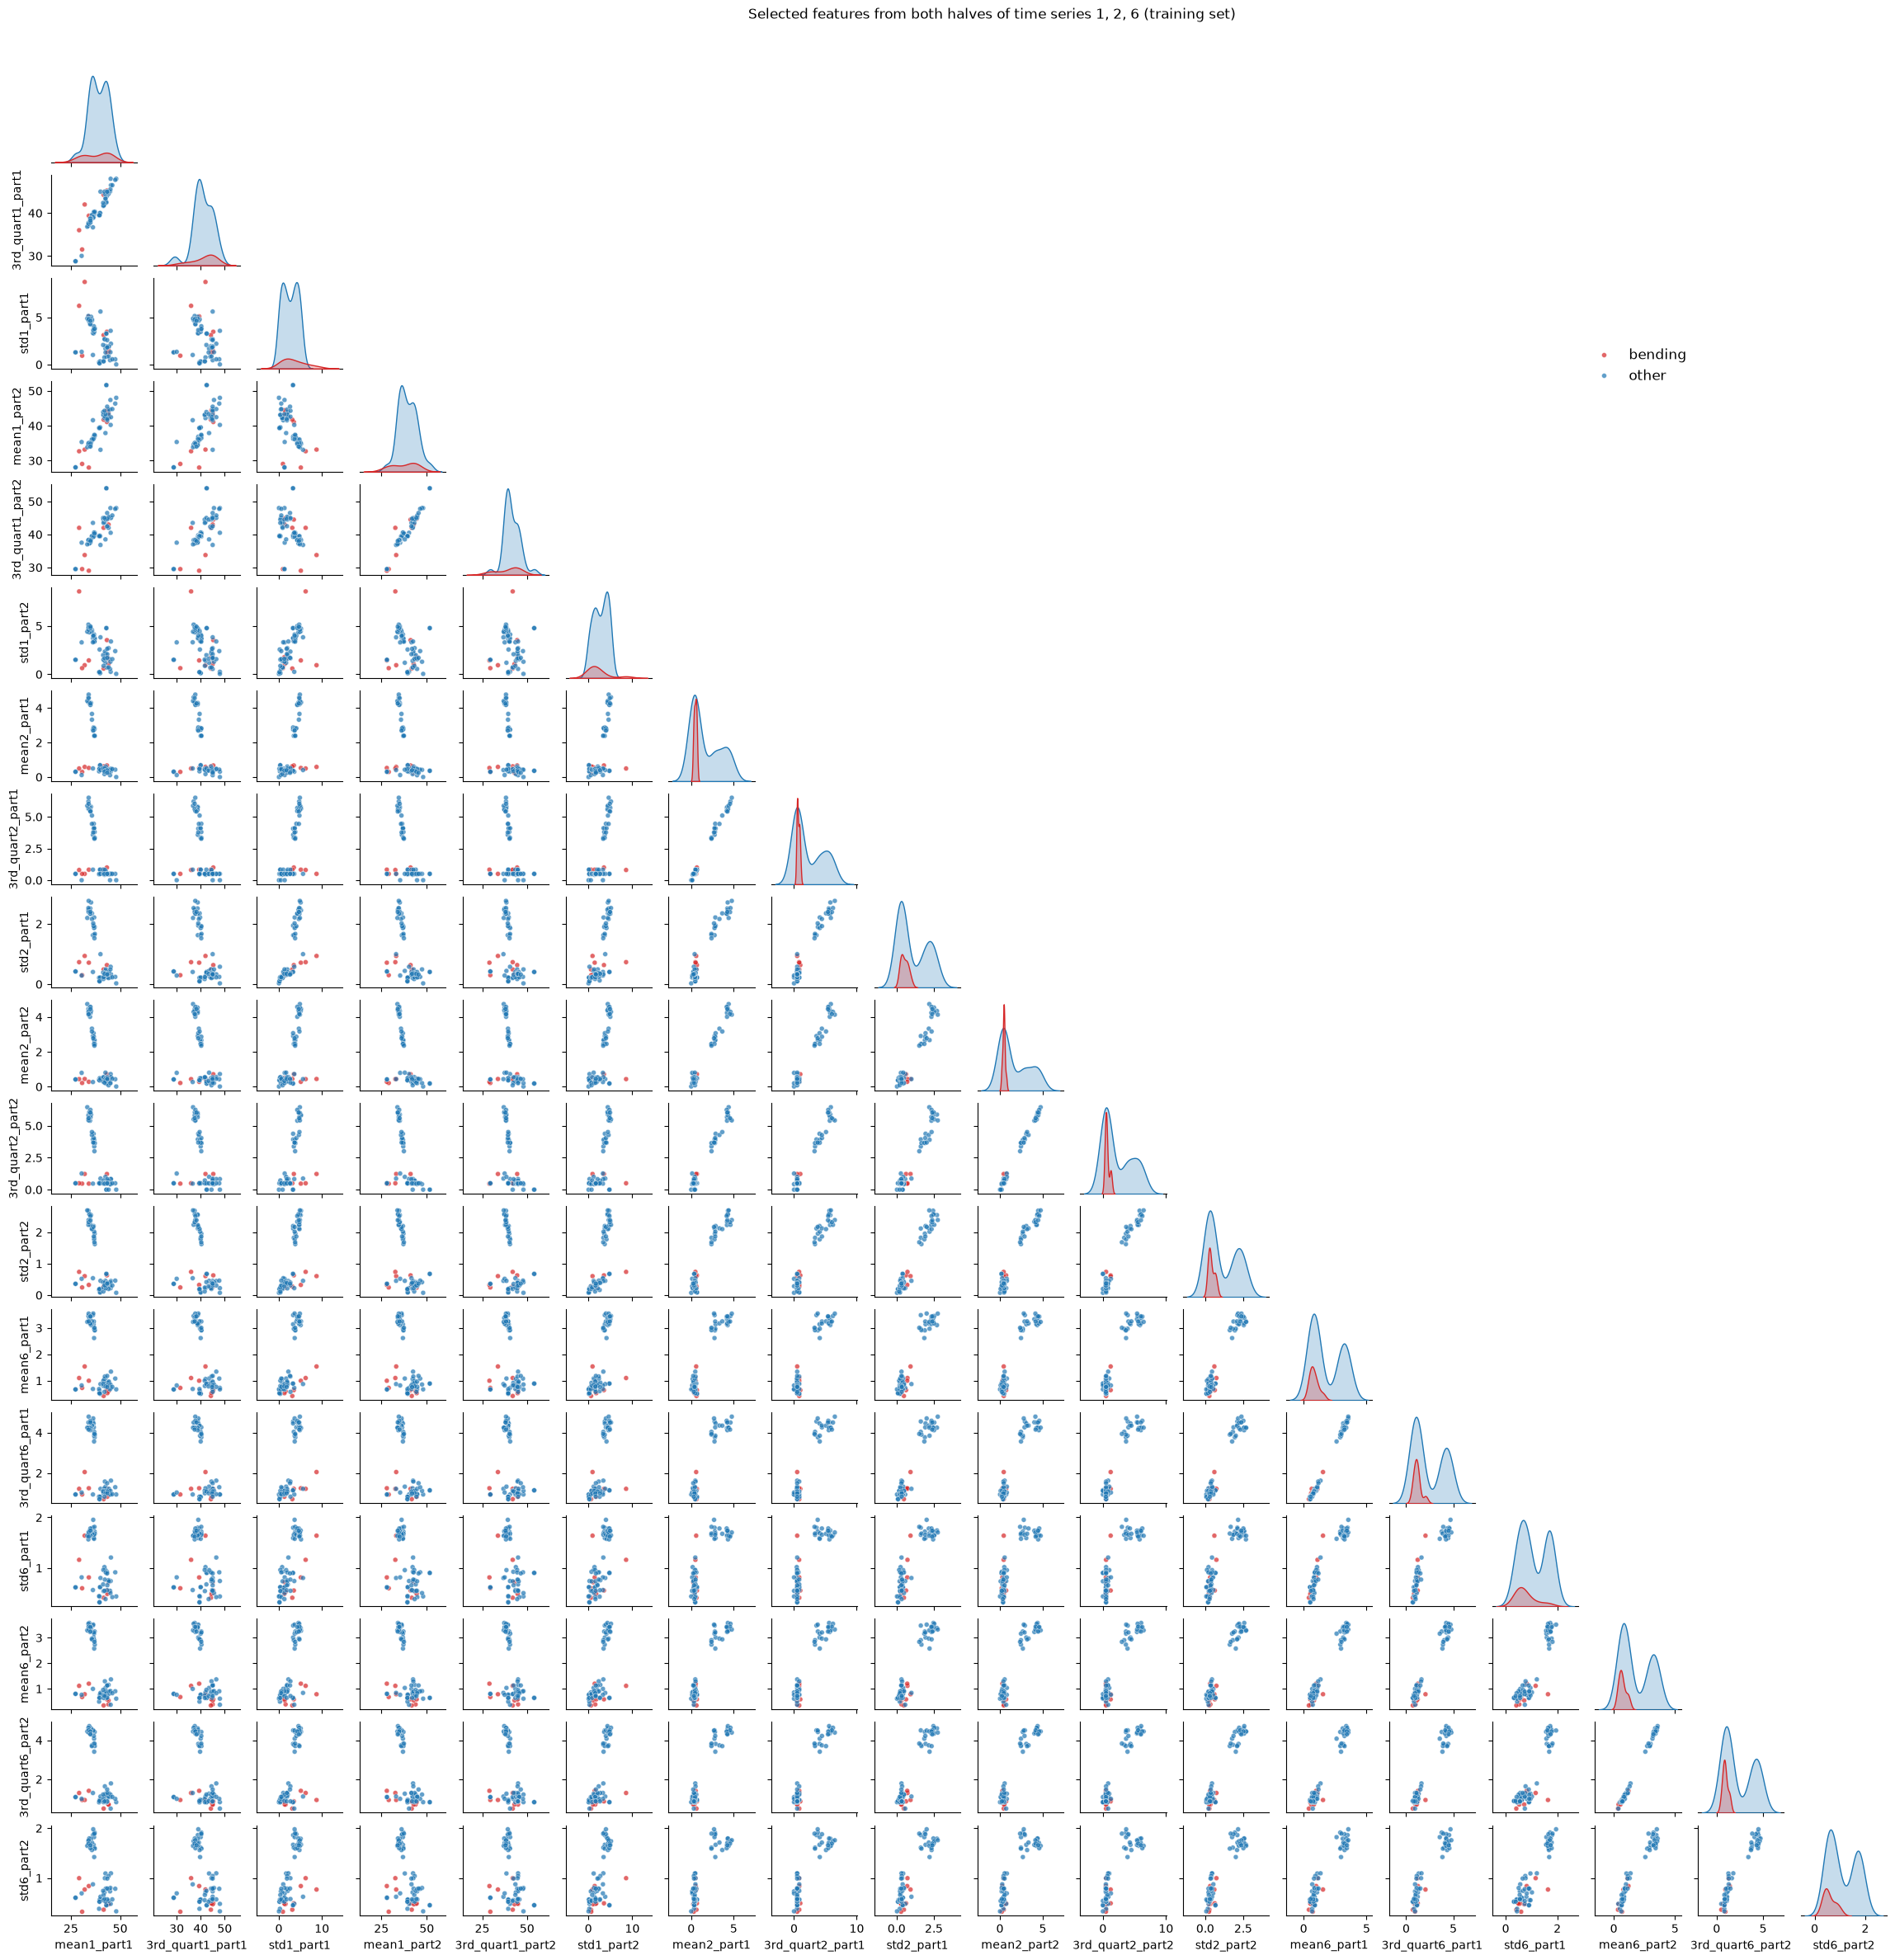

In [6]:
# Split each series into 2 halves, then plot the same features from both halves of series 1, 2, 6
X_train2, _, _ = build_dataset(train_records, l=2)
print('Train features with l=2:', X_train2.shape)

sel2 = [f'{stat}{i}_part{j}' for i in (1, 2, 6) for j in (1, 2) for stat in ('mean', '3rd_quart', 'std')]
plot_df2 = X_train2[sel2].assign(label=y_train.map({1: 'bending', 0: 'other'}))
g2 = sns.pairplot(plot_df2, hue='label', palette={'bending': 'tab:red', 'other': 'tab:blue'},
                  corner=True, diag_kind='kde', height=1.3,
                  plot_kws={'s': 18, 'alpha': 0.7})
sns.move_legend(g2, 'upper right', bbox_to_anchor=(0.85, 0.85), title=None, fontsize=12)
g2.figure.suptitle('Selected features from both halves of time series 1, 2, 6 (training set)', y=1.02)
plt.show()

**NOTE**<br>
With l = 2 there are 84 features (69 × 84). The patterns are essentially the same as in 2(a)i:

- Bending is still clearly separated from the dynamic activities (high variance in series 2 and 6),
  and still overlaps with the static activities in most panels.
- The two halves of the same feature are strongly correlated (e.g. mean2_part1 vs. mean2_part2),
  so splitting mainly duplicates information rather than revealing new structure.
- Bending points are slightly more spread out in individual halves (e.g. std1_part1, std6_part1),
  but no pair of features separates the two classes noticeably better than in 2(a)i.

**No considerable difference from 2(a)i.**

#### iii. Time Series Segments

**Cross-validation, the right way vs. the wrong way.** The wrong way is to select features with RFE on
the whole training set and then cross-validate the model on those features: the validation folds have
already influenced the selection, so the CV accuracy is optimistically biased. The right way, used here,
is to repeat the whole procedure (standardization, RFE, fitting) inside each fold, using only that fold's
training part, and evaluate on the held-out part.

Because bending is rare (9 of 69), **stratified 5-fold CV** is used so every fold keeps the class ratio.
Logistic regression uses a very large C (no L2 penalty). p ranges from 1 to 20, since 69 instances
cannot support many more parameters.

**NOTE**：For reproducibility, all random operations (CV fold splitting, case-control sampling, and the
liblinear / saga solvers) use a fixed random seed of 42, so every run gives the same results.

In [7]:
# Stratified 5-fold CV over (l, p); scaling and RFE are done inside each training fold
import time
C_BIG = 1e10                       # very large budget = no L2 regularization
L_RANGE, P_RANGE = range(1, 21), range(1, 21)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = y_train.to_numpy()

cv_acc = pd.DataFrame(index=list(L_RANGE), columns=list(P_RANGE), dtype=float)
start = time.time()
for l in L_RANGE:
    X_l = build_dataset(train_records, l)[0].to_numpy()
    fold_acc = np.zeros((5, len(P_RANGE)))
    for k, (tr, va) in enumerate(skf.split(X_l, y)):
        scaler = StandardScaler().fit(X_l[tr])
        Xtr, Xva = scaler.transform(X_l[tr]), scaler.transform(X_l[va])
        # One RFE run down to 1 feature gives a full ranking; top-p features = ranking <= p
        rank = RFE(LogisticRegression(C=C_BIG, max_iter=100), n_features_to_select=1).fit(Xtr, y[tr]).ranking_
        for m, p in enumerate(P_RANGE):
            cols = rank <= p
            clf = LogisticRegression(C=C_BIG, max_iter=100).fit(Xtr[:, cols], y[tr])
            fold_acc[k, m] = accuracy_score(y[va], clf.predict(Xva[:, cols]))
    cv_acc.loc[l] = fold_acc.mean(axis=0)
    print(f'l = {l:2d} done, best CV accuracy = {cv_acc.loc[l].max():.3f}  ({time.time() - start:.0f}s)')

l =  1 done, best CV accuracy = 0.986  (1s)
l =  2 done, best CV accuracy = 0.971  (2s)
l =  3 done, best CV accuracy = 0.943  (3s)
l =  4 done, best CV accuracy = 0.957  (5s)
l =  5 done, best CV accuracy = 0.956  (8s)
l =  6 done, best CV accuracy = 0.957  (11s)
l =  7 done, best CV accuracy = 0.943  (15s)
l =  8 done, best CV accuracy = 0.943  (19s)
l =  9 done, best CV accuracy = 0.942  (24s)
l = 10 done, best CV accuracy = 0.986  (29s)
l = 11 done, best CV accuracy = 0.971  (35s)
l = 12 done, best CV accuracy = 0.971  (42s)
l = 13 done, best CV accuracy = 0.971  (49s)
l = 14 done, best CV accuracy = 0.957  (58s)
l = 15 done, best CV accuracy = 0.929  (66s)
l = 16 done, best CV accuracy = 0.971  (76s)
l = 17 done, best CV accuracy = 0.957  (86s)
l = 18 done, best CV accuracy = 0.957  (97s)
l = 19 done, best CV accuracy = 0.986  (108s)
l = 20 done, best CV accuracy = 0.986  (120s)


In [8]:
# Best (l, p): highest mean CV accuracy; ties are broken by the smallest l, then the smallest p
best_l, best_p = cv_acc.stack().idxmax()
print(f'Best l = {best_l}, best p = {best_p}, CV accuracy = {cv_acc.loc[best_l, best_p]:.3f}')
cv_acc.round(3)

Best l = 1, best p = 8, CV accuracy = 0.986


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
1,0.885,0.885,0.957,0.957,0.929,0.943,0.957,0.986,0.986,0.986,0.971,0.971,0.971,0.957,0.971,0.971,0.971,0.971,0.971,0.957
2,0.899,0.942,0.957,0.957,0.943,0.957,0.971,0.957,0.943,0.943,0.913,0.913,0.927,0.927,0.943,0.927,0.943,0.927,0.943,0.943
3,0.899,0.899,0.913,0.943,0.929,0.943,0.943,0.943,0.929,0.943,0.943,0.943,0.943,0.943,0.929,0.929,0.929,0.929,0.929,0.943
4,0.943,0.900,0.929,0.914,0.914,0.929,0.914,0.914,0.914,0.914,0.929,0.943,0.943,0.943,0.957,0.943,0.943,0.943,0.943,0.929
5,0.943,0.913,0.913,0.943,0.929,0.927,0.927,0.942,0.942,0.942,0.956,0.956,0.942,0.899,0.899,0.913,0.927,0.927,0.913,0.913
6,0.957,0.927,0.929,0.929,0.943,0.943,0.943,0.929,0.929,0.929,0.943,0.943,0.957,0.957,0.943,0.943,0.943,0.943,0.929,0.943
7,0.899,0.913,0.913,0.913,0.927,0.942,0.943,0.942,0.942,0.942,0.942,0.913,0.913,0.885,0.885,0.899,0.913,0.913,0.913,0.913
8,0.913,0.914,0.914,0.899,0.913,0.914,0.900,0.886,0.929,0.929,0.929,0.914,0.929,0.943,0.943,0.943,0.943,0.943,0.943,0.929
9,0.929,0.914,0.913,0.942,0.942,0.942,0.912,0.912,0.913,0.913,0.913,0.913,0.929,0.929,0.929,0.914,0.914,0.914,0.900,0.900
10,0.927,0.957,0.929,0.913,0.929,0.957,0.943,0.943,0.943,0.957,0.957,0.943,0.943,0.943,0.943,0.971,0.957,0.986,0.986,0.986


**NOTE**<br>
Feature selection uses RFE (backward selection), the alternative allowed in the problem.
The best pair is **(l, p) = (1, 8)** with a 5-fold CV accuracy of **0.986**.

- l = 10, 19 and 20 reach the same accuracy; ties are broken toward the simplest model (smallest l).
- Splitting the series does not improve accuracy, consistent with 2(a)ii.
- All l give high accuracy (0.93–0.99). With about 14 instances per fold, one misclassification
  changes a fold's accuracy by about 7%, so the differences between l values are small.

#### iv. Confusion Matrix

Selected features: ['3rd_quart1', '3rd_quart3', 'max4', '1st_quart4', 'min5', 'max5', 'mean5', '1st_quart6']


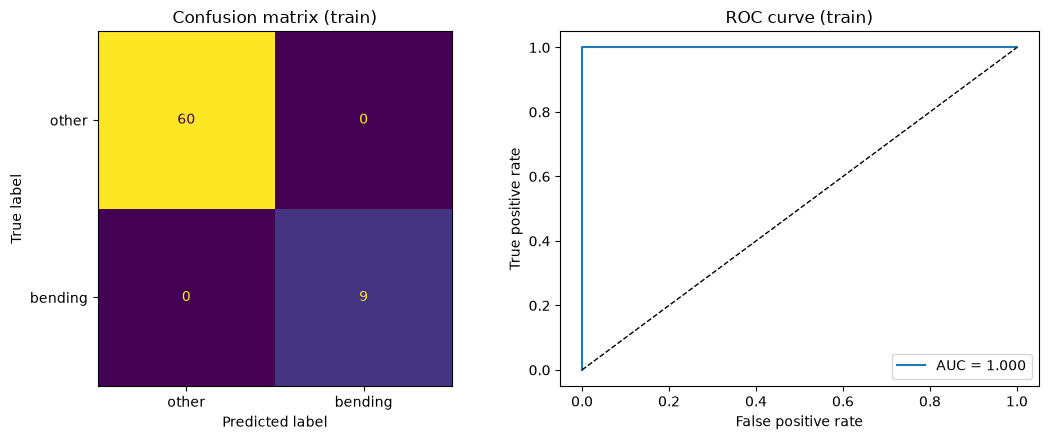

In [9]:
# Refit on the full training set with the best (l, p): standardize, RFE to best_p features, logistic regression
X_tr_best = build_dataset(train_records, best_l)[0]     # features with the CV-selected l
X_te_best = build_dataset(test_records, best_l)[0]
X1_tr = X_tr_best.to_numpy()
final_scaler = StandardScaler().fit(X1_tr)
Xs_tr = final_scaler.transform(X1_tr)
final_rfe = RFE(LogisticRegression(C=C_BIG, max_iter=100), n_features_to_select=best_p).fit(Xs_tr, y)
support = final_rfe.support_
sel_feats = list(X_tr_best.columns[support])
final_clf = LogisticRegression(C=C_BIG, max_iter=100).fit(Xs_tr[:, support], y)
print('Selected features:', sel_feats)

# Confusion matrix and ROC curve on the training data
prob_tr = final_clf.predict_proba(Xs_tr[:, support])[:, 1]
pred_tr = final_clf.predict(Xs_tr[:, support])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_tr), display_labels=['other', 'bending']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Confusion matrix (train)')
fpr, tpr, _ = roc_curve(y, prob_tr)
axes[1].plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve (train)')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

In [10]:
# Coefficients from sklearn and statsmodels, with p-values from statsmodels (same standardized features)
X_sm = sm.add_constant(pd.DataFrame(Xs_tr[:, support], columns=sel_feats))
sm_res = sm.Logit(y, X_sm).fit(disp=0, maxiter=100)
coef_table = pd.DataFrame({
    'beta (sklearn)': np.r_[final_clf.intercept_, final_clf.coef_.ravel()],
    'beta (statsmodels)': sm_res.params.values,
    'p-value': sm_res.pvalues.values,
}, index=['intercept'] + sel_feats).round(4)
coef_table

,beta (sklearn),beta (statsmodels),p-value
intercept,-12.1373,-40.1685,0.9997
3rd_quart1,-3.6776,-11.1416,0.9999
3rd_quart3,-2.0185,-5.9303,1.0000
max4,2.9100,9.1388,1.0000
1st_quart4,-3.1190,-7.2600,1.0000
min5,4.6210,19.2343,1.0000
max5,5.0632,17.5209,0.9999
mean5,3.1843,6.3929,1.0000
1st_quart6,-3.1338,-14.3035,1.0000


**NOTE**<br>
RFE selected 8 features: 3rd_quart1, 3rd_quart3, max4, 1st_quart4, min5, max5, mean5, 1st_quart6.

- On the training data the classifier is perfect: all 60 other and 9 bending instances are correctly
  classified (no errors), and the ROC curve gives **AUC = 1.000**.
- The p-values of all coefficients are about 1, and the statsmodels estimates are much larger than
  the sklearn ones. This happens because the training classes are perfectly separable: the maximum
  likelihood estimates diverge to infinity, so the standard errors explode and the p-values are not
  meaningful. The sklearn coefficients are finite only because the solver stops after 100 iterations.

#### v. Test Classifier

Test accuracy = 1.000 | CV accuracy = 0.986
Test AUC = 1.000


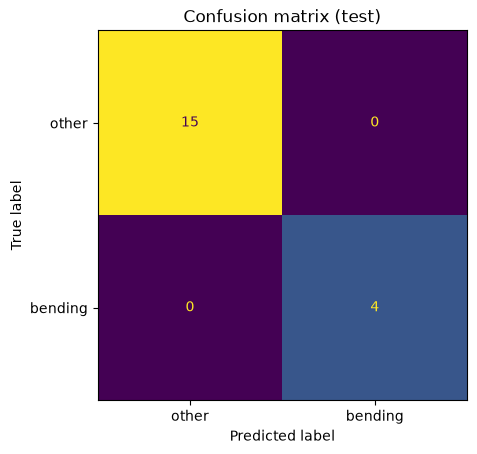

In [11]:
# Test with best_l features from the test set, using the training scaler and the same selected features
Xs_te = final_scaler.transform(X_te_best.to_numpy())
pred_te = final_clf.predict(Xs_te[:, support])
test_acc = accuracy_score(y_test, pred_te)
print(f'Test accuracy = {test_acc:.3f} | CV accuracy = {cv_acc.loc[best_l, best_p]:.3f}')

# Test AUC of the RFE model
prob_te = final_clf.predict_proba(Xs_te[:, support])[:, 1]
print(f'Test AUC = {roc_auc_score(y_test, prob_te):.3f}')

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_te), display_labels=['other', 'bending']).plot(colorbar=False)
plt.title('Confusion matrix (test)')
plt.show()

**NOTE**<br>
The test set is transformed with the training scaler and the same 8 selected features (l = 1).
**Test accuracy = 1.000** (15 other and 4 bending, all correct), compared with **CV accuracy = 0.986**.
The two are consistent: with only 19 test instances, a single error would change the test accuracy
by about 5%, so the small gap is not meaningful. The model generalizes well.

#### vi. Separation

**Yes.** The training classes are perfectly separated by the selected features (no training errors,
AUC = 1.000 in 2(a)iv). Under perfect separation the logistic regression likelihood has no finite
maximum, so the coefficients diverge: the statsmodels estimates are several times larger than the
sklearn ones (which stop at max_iter = 100), and all p-values are about 1 because the standard errors
blow up. The parameter estimates are therefore unstable, even though the classifier itself predicts well.

#### vii. Imbalance

pi = 0.130, pi_sample = 0.500
Intercept before = -5.7853, after adjustment = -7.6825


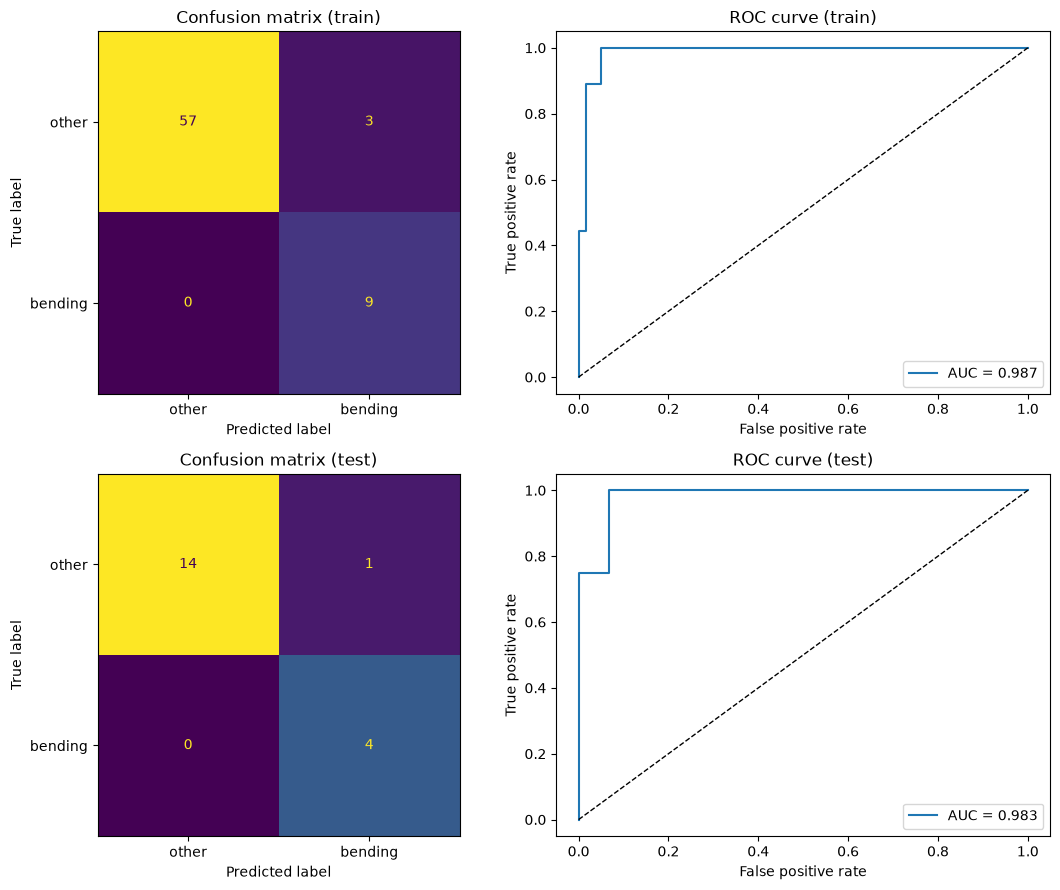

In [12]:
# Case-control sampling: keep all 9 bending (cases) and randomly sample 9 other (controls)
rng = np.random.default_rng(42)
case_idx = np.where(y == 1)[0]
ctrl_idx = rng.choice(np.where(y == 0)[0], size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, ctrl_idx]
cc_clf = LogisticRegression(C=C_BIG, max_iter=100).fit(Xs_tr[cc_idx][:, support], y[cc_idx])

# Adjust the intercept from the sample proportion (pi_s) to the true proportion (pi)
pi, pi_s = y.mean(), y[cc_idx].mean()
b0_raw = cc_clf.intercept_[0]
cc_clf.intercept_ = cc_clf.intercept_ + np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))
print(f'pi = {pi:.3f}, pi_sample = {pi_s:.3f}')
print(f'Intercept before = {b0_raw:.4f}, after adjustment = {cc_clf.intercept_[0]:.4f}')

# Confusion matrix and ROC of the adjusted model on the full training set and the test set
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (name, Xe, ye) in enumerate([('train', Xs_tr, y), ('test', Xs_te, y_test.to_numpy())]):
    prob = cc_clf.predict_proba(Xe[:, support])[:, 1]
    ConfusionMatrixDisplay(confusion_matrix(ye, cc_clf.predict(Xe[:, support])),
                           display_labels=['other', 'bending']).plot(ax=axes[row, 0], colorbar=False)
    axes[row, 0].set_title(f'Confusion matrix ({name})')
    fpr, tpr, _ = roc_curve(ye, prob)
    axes[row, 1].plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
    axes[row, 1].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[row, 1].set(xlabel='False positive rate', ylabel='True positive rate', title=f'ROC curve ({name})')
    axes[row, 1].legend(loc='lower right')
plt.tight_layout()
plt.show()

**NOTE**<br>
**Yes, the classes are imbalanced**: 9 bending vs. 60 other in training (13%), 4 vs. 15 in test.<br>
Case-control sampling keeps all 9 bending instances and randomly samples 9 other instances (1:1).<br>
The intercept is adjusted from the sample proportion (0.5) to the true proportion (0.130):<br>
β0 changes from −5.785 to −7.683 (a shift of log(0.130/0.870) − log(0.5/0.5) ≈ −1.90).

| Data  | Accuracy      | Errors            | AUC   |
|-------|---------------|-------------------|-------|
| Train | 66/69 = 0.957 | 3 false positives | 0.987 |
| Test  | 18/19 = 0.947 | 1 false positive  | 0.983 |

All bending instances are still detected; the only errors are other instances predicted as bending.
The model is slightly worse than the full-data model in 2(a)iv–v, because it is trained on only
18 instances and discards most of the information in the majority class.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [13]:
# L1-penalized logistic regression: stratified 5-fold CV over (l, C); scaling is fit inside each fold
C_GRID = np.logspace(-2, 2, 17)        # 0.01 to 100
cv_l1 = pd.DataFrame(index=list(L_RANGE), columns=C_GRID, dtype=float)
for l in L_RANGE:
    X_l = build_dataset(train_records, l)[0]
    for C in C_GRID:
        pipe = Pipeline([('scale', StandardScaler()),
                         ('lr', LogisticRegression(penalty='l1', solver='liblinear', C=C,random_state=42))])
        cv_l1.loc[l, C] = cross_val_score(pipe, X_l, y, cv=skf, scoring='accuracy').mean()

# Best (l, C); ties are broken by the smallest l, then the smallest C (strongest penalty)
best_l1, best_C = cv_l1.stack().idxmax()
print(f'Best l = {best_l1}, best C = {best_C:.4f}, CV accuracy = {cv_l1.loc[best_l1, best_C]:.3f}')
print('Best CV accuracy for each l:')
print(cv_l1.max(axis=1).round(3).to_string())

Best l = 12, best C = 0.5623, CV accuracy = 0.986
Best CV accuracy for each l:
1     0.957
2     0.957
3     0.971
4     0.971
5     0.942
6     0.957
7     0.942
8     0.929
9     0.927
10    0.971
11    0.971
12    0.986
13    0.971
14    0.971
15    0.943
16    0.943
17    0.957
18    0.971
19    0.986
20    0.971


**NOTE**<br>
L1-penalized logistic regression (liblinear, standardized features) is cross-validated over l = 1–20
and 17 values of C from 0.01 to 100, using the same stratified 5 folds as in 2(a)iii.
The best pair is **(l, C) = (12, 0.562)** with a CV accuracy of **0.986**, the same as the best
accuracy of RFE in 2(a)iii. l = 19 ties with it; the smallest l is chosen.
The best accuracy for each l ranges from 0.927 to 0.986, so as before, the choice of l matters little.

Non-zero coefficients: 7 of 504
max1_part7         -0.5239
median4_part9      -0.0131
3rd_quart4_part9   -0.0238
median5_part2       0.1659
1st_quart5_part2    1.5954
min5_part11         0.3674
max6_part11        -0.3045

Test accuracy = 0.947


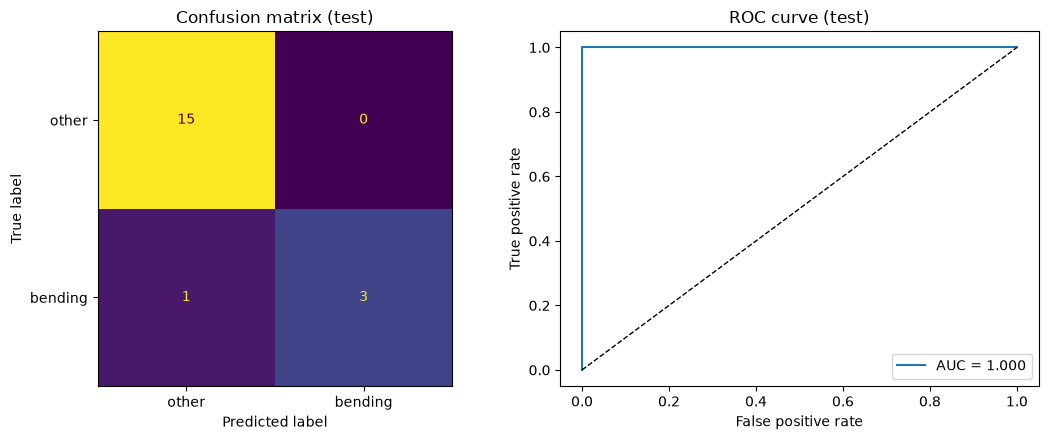

In [14]:
# Refit L1 model on the full training set with the best (l, C); evaluate on train and test
X_tr_l1, _, _ = build_dataset(train_records, best_l1)
X_te_l1, _, _ = build_dataset(test_records, best_l1)
l1_model = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='liblinear', C=best_C,random_state=42))]).fit(X_tr_l1, y)
coefs = pd.Series(l1_model['lr'].coef_.ravel(), index=X_tr_l1.columns)
print(f'Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}')
print(coefs[coefs != 0].round(4).to_string())

pred_te_l1 = l1_model.predict(X_te_l1)
print(f'\nTest accuracy = {accuracy_score(y_test, pred_te_l1):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_te_l1), display_labels=['other', 'bending']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Confusion matrix (test)')
fpr, tpr, _ = roc_curve(y_test, l1_model.predict_proba(X_te_l1)[:, 1])
axes[1].plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve (test)')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

**NOTE**<br>
With (l, C) = (12, 0.562), L1 keeps only **7 of 504** features (from series 1, 4, 5 and 6), with small, finite coefficients.
On the test set: **accuracy = 0.947** (one bending instance predicted as other), **AUC = 1.000**.
AUC = 1 means every bending instance gets a higher predicted probability than every other instance;
the one error comes from the 0.5 threshold, because the L1 penalty shrinks the coefficients and keeps
the probabilities moderate.

#### ii. Comparison

| Method              | Best setting  | Features used | CV accuracy | Test accuracy | Test AUC |
|---------------------|---------------|---------------|-------------|---------------|----------|
| RFE (2(a))          | l = 1, p = 8  | 8 of 42       | 0.986       | 1.000         | 1.000    |
| L1 penalty (2(b))   | l = 12, C = 0.562 | 7 of 504  | 0.986       | 0.947         | 1.000    |

**(1)Performance.** <br>The two methods are essentially **equivalent**: they reach the same CV accuracy, and the test
accuracies differ by one instance out of 19, which is within noise. RFE is marginally better on this
test set, but L1 ranks the test instances perfectly (AUC = 1.000) and gives stable, finite coefficients,
whereas the unpenalized model in 2(a) has diverging coefficients and meaningless p-values because the
classes are separable.

**(2)Ease of implementation.** **<br>L1 is easier**. It selects features and fits the model in one convex
optimization, and sklearn handles it with a single estimator. The p-value / RFE approach needs a
separate selection loop (or repeated fitting and pruning by p-values), an extra library for p-values,
and its p-values break down under perfect separation.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [15]:
# L1-penalized multinomial regression: stratified 5-fold CV over (l, C) on all 7 activities
y_multi = act_train.to_numpy()
C_GRID_M = np.logspace(-1, 2, 7)       # 0.1 to 100
cv_mn = pd.DataFrame(index=list(L_RANGE), columns=C_GRID_M, dtype=float)
start = time.time()
for l in L_RANGE:
    X_l = build_dataset(train_records, l)[0]
    for C in C_GRID_M:
        pipe = Pipeline([('scale', StandardScaler()),
                         ('lr', LogisticRegression(penalty='l1', solver='saga', C=C, max_iter=1000,random_state=42))])
        cv_mn.loc[l, C] = cross_val_score(pipe, X_l, y_multi, cv=skf, scoring='accuracy').mean()
    print(f'l = {l:2d} done, best CV accuracy = {cv_mn.loc[l].max():.3f}  ({time.time() - start:.0f}s)')

# Best (l, C); ties are broken by the smallest l, then the smallest C
best_lm, best_Cm = cv_mn.stack().idxmax()
print(f'\nBest l = {best_lm}, best C = {best_Cm:.4f}, CV accuracy = {cv_mn.loc[best_lm, best_Cm]:.3f}')

l =  1 done, best CV accuracy = 0.900  (3s)
l =  2 done, best CV accuracy = 0.884  (9s)
l =  3 done, best CV accuracy = 0.871  (18s)
l =  4 done, best CV accuracy = 0.886  (30s)
l =  5 done, best CV accuracy = 0.886  (45s)
l =  6 done, best CV accuracy = 0.886  (63s)
l =  7 done, best CV accuracy = 0.870  (84s)
l =  8 done, best CV accuracy = 0.856  (108s)
l =  9 done, best CV accuracy = 0.871  (135s)
l = 10 done, best CV accuracy = 0.856  (165s)
l = 11 done, best CV accuracy = 0.856  (198s)
l = 12 done, best CV accuracy = 0.886  (235s)
l = 13 done, best CV accuracy = 0.871  (274s)
l = 14 done, best CV accuracy = 0.813  (317s)
l = 15 done, best CV accuracy = 0.842  (362s)
l = 16 done, best CV accuracy = 0.827  (411s)
l = 17 done, best CV accuracy = 0.857  (463s)
l = 18 done, best CV accuracy = 0.885  (517s)
l = 19 done, best CV accuracy = 0.842  (575s)
l = 20 done, best CV accuracy = 0.886  (636s)

Best l = 1, best C = 1.0000, CV accuracy = 0.900


Test accuracy = 0.895 | Test error = 0.105
Features with a non-zero coefficient in any class: 18 of 42


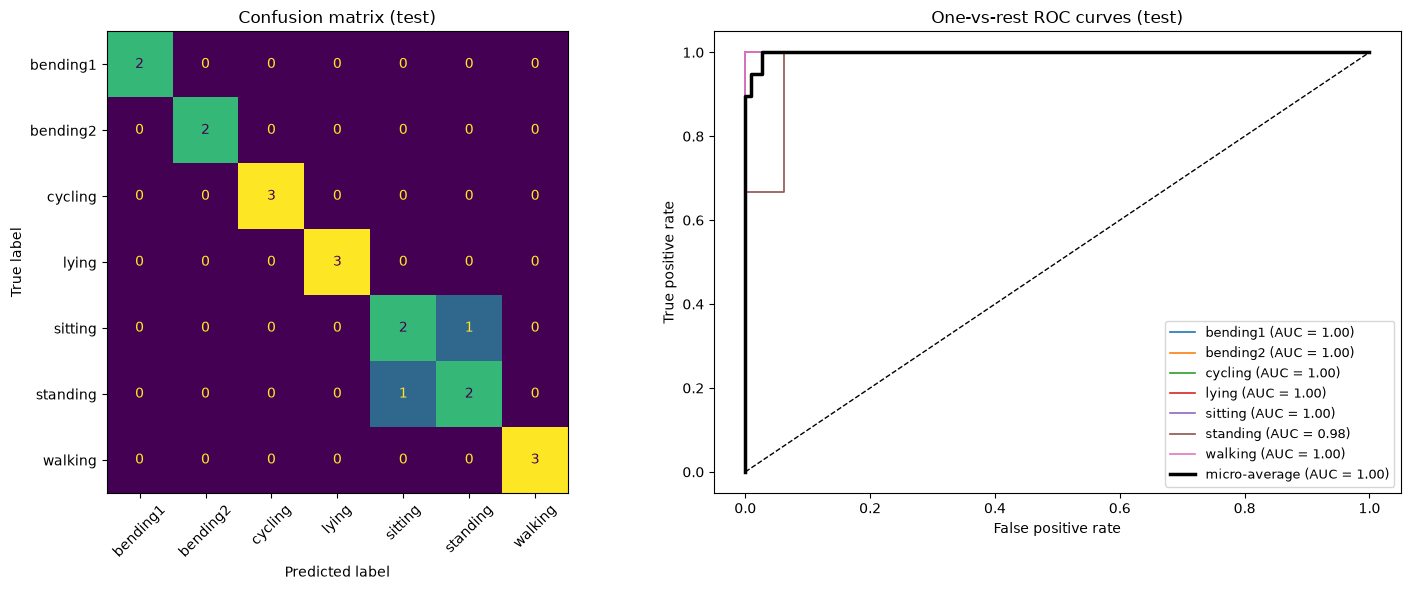

Macro-average AUC = 0.997


In [16]:
# Refit the best L1 multinomial model on the full training set and evaluate on the test set
X_tr_m, _, _ = build_dataset(train_records, best_lm)
X_te_m, _, _ = build_dataset(test_records, best_lm)
mn_model = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='saga', C=best_Cm, max_iter=1000,random_state=42))]).fit(X_tr_m, y_multi)
pred_te_m = mn_model.predict(X_te_m)
acc_m = accuracy_score(act_test, pred_te_m)
print(f'Test accuracy = {acc_m:.3f} | Test error = {1 - acc_m:.3f}')
print(f'Features with a non-zero coefficient in any class: '
      f'{(mn_model["lr"].coef_ != 0).any(axis=0).sum()} of {X_tr_m.shape[1]}')

classes = mn_model.classes_
P_te = mn_model.predict_proba(X_te_m)
Y_te = label_binarize(act_test, classes=classes)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Multiclass confusion matrix (rows = true activity, columns = predicted activity)
ConfusionMatrixDisplay(confusion_matrix(act_test, pred_te_m, labels=classes),
                       display_labels=classes).plot(ax=axes[0], colorbar=False, xticks_rotation=45)
axes[0].set_title('Confusion matrix (test)')

# One-vs-rest ROC curve for each class, plus the micro-average over all classes
for k, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y_te[:, k], P_te[:, k])
    axes[1].plot(fpr, tpr, lw=1.2, label=f'{c} (AUC = {auc(fpr, tpr):.2f})')
fpr, tpr, _ = roc_curve(Y_te.ravel(), P_te.ravel())
axes[1].plot(fpr, tpr, 'k-', lw=2.5, label=f'micro-average (AUC = {auc(fpr, tpr):.2f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='One-vs-rest ROC curves (test)')
axes[1].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
print(f'Macro-average AUC = {roc_auc_score(act_test, P_te, multi_class="ovr", average="macro", labels=classes):.3f}')

**NOTE：** **Multiclass confusion matrix and ROC.**
- The confusion matrix becomes K × K (here 7 × 7): row i, column j counts test instances of activity i
  predicted as activity j. Correct predictions lie on the diagonal; off-diagonal cells show which
  activities are confused with each other.
- ROC curves are defined for binary problems, so the usual extension is **one-vs-rest**: for each class k,
  treat k as positive and all other classes as negative, and use the predicted probability of class k
  as the score. This gives one ROC curve and AUC per class. They are summarized by the
  **micro-average** (pool all one-vs-rest decisions into a single ROC curve) and the
  **macro-average** (the mean of the per-class AUCs).

**CONCLUSION**<br>
The best pair is **(l, C) = (1, 1.0)** with a CV accuracy of **0.900**. As in the binary case,
splitting the series does not help: the best accuracy for each l ranges from 0.813 to 0.900.
Note that bending2 has only 4 training instances, so one CV fold contains no bending2 instance.

The final model uses 18 of the 42 features (non-zero in at least one class).
**Test accuracy = 0.895, test error = 0.105** (2 of 19 misclassified).

- The confusion matrix shows that bending1, bending2, cycling, lying and walking are all classified
  correctly. The only errors are between **sitting and standing** (one each way), the two static
  activities with the most similar posture.
- The one-vs-rest AUCs are 1.00 for every class except standing (0.98); the micro-average AUC is 1.00
  and the **macro-average AUC is 0.997**.

#### ii. Naive Bayes

In [17]:
# Naive Bayes on all 7 activities: stratified 5-fold CV over l for Gaussian and Multinomial NB
# Raw (non-negative) features are used: Multinomial NB requires non-negative input
nb_models = {'Gaussian NB': GaussianNB(), 'Multinomial NB': MultinomialNB()}
cv_nb = pd.DataFrame(index=list(L_RANGE), columns=list(nb_models), dtype=float)
for l in L_RANGE:
    X_l = build_dataset(train_records, l)[0]
    for name, model in nb_models.items():
        cv_nb.loc[l, name] = cross_val_score(model, X_l, y_multi, cv=skf, scoring='accuracy').mean()

best_l_nb = cv_nb.idxmax()             # smallest l with the highest CV accuracy, per model
print('Best l:', best_l_nb.to_dict())
cv_nb.round(3)

Best l: {'Gaussian NB': 1, 'Multinomial NB': 1}


,Gaussian NB,Multinomial NB
1,0.857,0.871
2,0.827,0.770
3,0.698,0.813
4,0.697,0.827
5,0.637,0.827
6,0.652,0.813
7,0.596,0.799
8,0.638,0.770
9,0.565,0.799
10,0.667,0.785


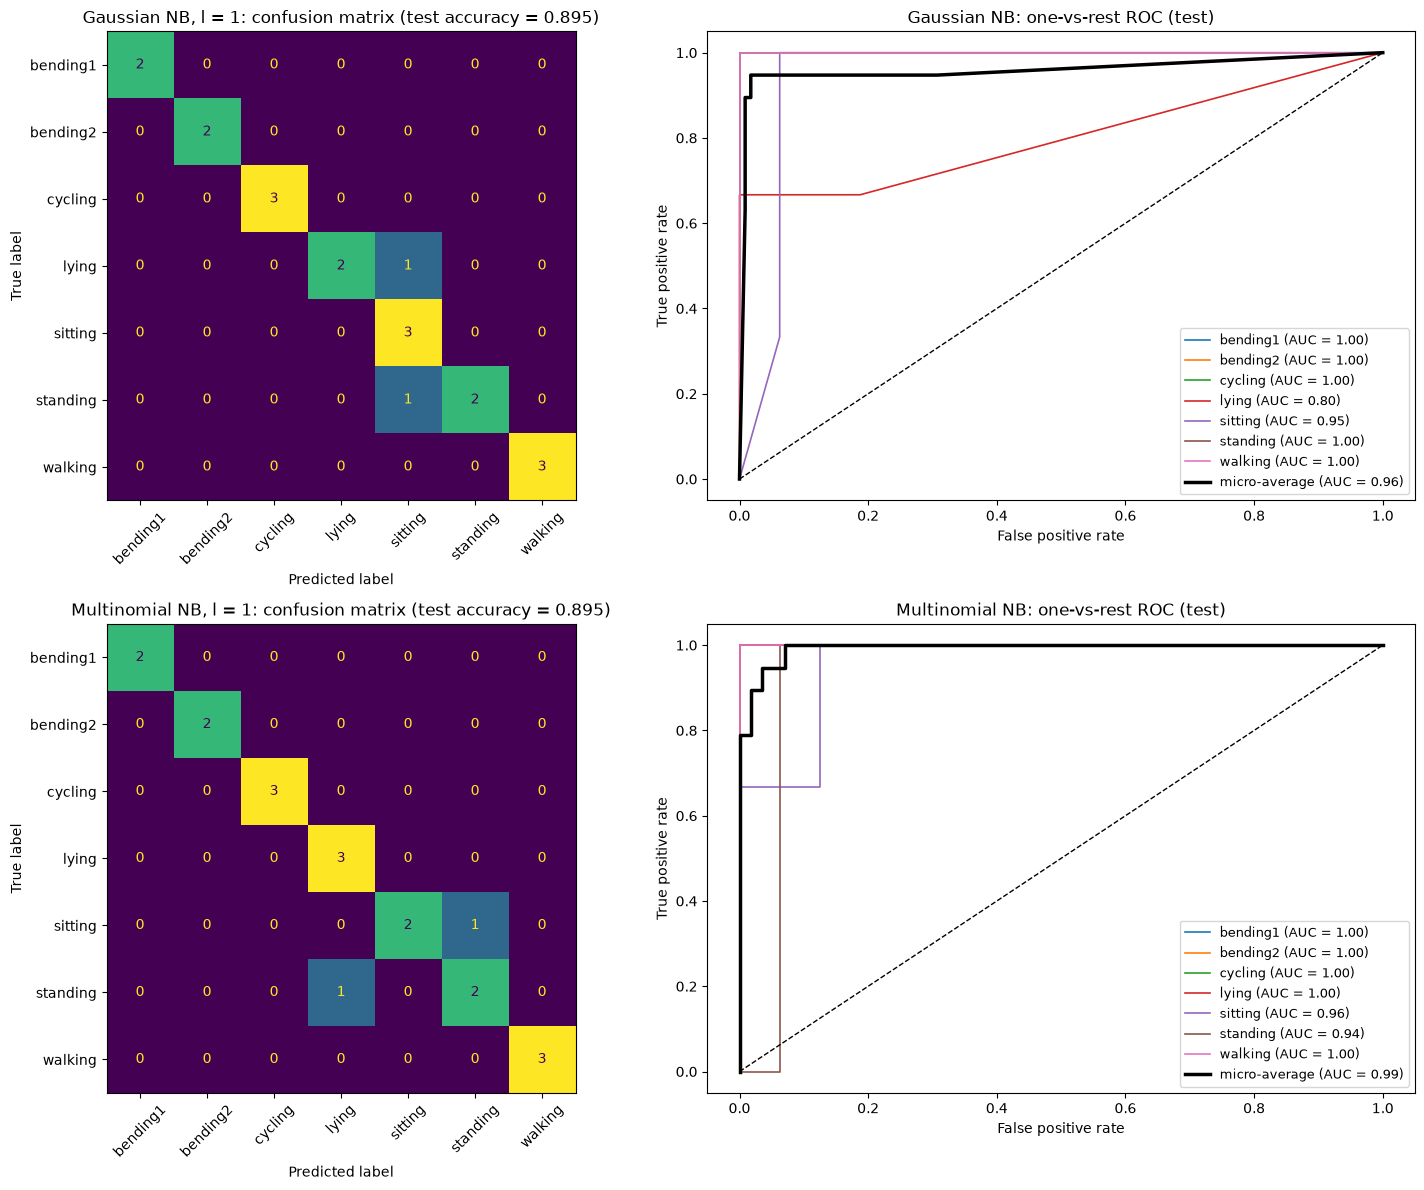

,best l,CV accuracy,test accuracy,test macro AUC
Gaussian NB,1,0.857,0.895,0.964
Multinomial NB,1,0.871,0.895,0.985


In [18]:
# Refit each Naive Bayes model with its best l; confusion matrix and one-vs-rest ROC on the test set
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
nb_results = {}
for row, (name, model) in enumerate(nb_models.items()):
    l = best_l_nb[name]
    X_tr_nb = build_dataset(train_records, l)[0]
    X_te_nb = build_dataset(test_records, l)[0]
    model.fit(X_tr_nb, y_multi)
    pred, P = model.predict(X_te_nb), model.predict_proba(X_te_nb)
    acc = accuracy_score(act_test, pred)
    nb_results[name] = {'best l': l, 'CV accuracy': cv_nb.loc[l, name], 'test accuracy': acc,
                        'test macro AUC': roc_auc_score(act_test, P, multi_class='ovr', average='macro', labels=model.classes_)}

    ConfusionMatrixDisplay(confusion_matrix(act_test, pred, labels=model.classes_),
                           display_labels=model.classes_).plot(ax=axes[row, 0], colorbar=False, xticks_rotation=45)
    axes[row, 0].set_title(f'{name}, l = {l}: confusion matrix (test accuracy = {acc:.3f})')

    Y = label_binarize(act_test, classes=model.classes_)
    for k, c in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(Y[:, k], P[:, k])
        axes[row, 1].plot(fpr, tpr, lw=1.2, label=f'{c} (AUC = {auc(fpr, tpr):.2f})')
    fpr, tpr, _ = roc_curve(Y.ravel(), P.ravel())
    axes[row, 1].plot(fpr, tpr, 'k-', lw=2.5, label=f'micro-average (AUC = {auc(fpr, tpr):.2f})')
    axes[row, 1].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[row, 1].set(xlabel='False positive rate', ylabel='True positive rate', title=f'{name}: one-vs-rest ROC (test)')
    axes[row, 1].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
pd.DataFrame(nb_results).T.astype({'best l': int}).round(3)

**NOTE**<br>
Both Naive Bayes models are cross-validated over l in the same way; both choose **l = 1**.

| Model          | CV accuracy | Test accuracy | Test macro AUC | Test errors                          |
|----------------|-------------|---------------|----------------|--------------------------------------|
| Gaussian NB    | 0.857       | 0.895         | 0.964          | lying → sitting, standing → sitting  |
| Multinomial NB | 0.871       | 0.895         | 0.985          | sitting → standing, standing → lying |

- Both make 2 errors out of 19, all among the static activities (lying, sitting, standing).
- Multinomial NB is slightly better in CV accuracy and macro AUC. Gaussian NB has a weaker ROC for
  lying (AUC = 0.80), because one lying instance is confidently predicted as sitting.
- Gaussian NB degrades quickly as l grows (CV accuracy falls from 0.857 to about 0.5), while
  Multinomial NB stays between 0.76 and 0.87. With more segments there are many more strongly
  correlated features, which violates the independence assumption, and Gaussian NB must also
  estimate a separate variance for every feature from very few instances per class.

#### iii. Comparison

| Method                         | Best l | CV accuracy | Test accuracy | Test macro AUC |
|--------------------------------|--------|-------------|---------------|----------------|
| L1-penalized multinomial LR    | 1      | **0.900**   | 0.895         | **0.997**      |
| Gaussian NB                    | 1      | 0.857       | 0.895         | 0.964          |
| Multinomial NB                 | 1      | 0.871       | 0.895         | 0.985          |

**L1-penalized multinomial logistic regression is the best method for this problem.** All three
reach the same test accuracy (2 errors out of 19, always among the static activities), but the
logistic regression has the highest CV accuracy and the highest macro AUC, meaning it ranks the
classes most reliably. It also does not rely on the independence assumption, which is clearly
violated here (e.g. mean and 3rd quartile of the same series are almost perfectly correlated),
and the L1 penalty selects a compact set of 18 features. Naive Bayes is much faster and simpler,
but less accurate and, for Gaussian NB, very sensitive to l.

## 3. ISLR 4.8.3

The Bayes classifier assigns $x$ to the class with the largest posterior probability

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}, \qquad
f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, so it is equivalent to maximizing $\pi_k f_k(x)$,
or its logarithm. Dropping the constant $-\tfrac12\log(2\pi)$, which is common to all classes,
the discriminant function is

$$\delta_k(x) = \log \pi_k - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}
= -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k .$$

The boundary between classes $k$ and $l$ is where $\delta_k(x) = \delta_l(x)$:

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right) x^2
+ \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right) x
+ \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\pi_k}{\pi_l} + \log\frac{\sigma_l}{\sigma_k}\right) = 0 .$$

Because the variances are class-specific, $\sigma_k \neq \sigma_l$ in general, so the coefficient of $x^2$
does not vanish. The discriminant functions, and hence the decision boundaries, are **quadratic in $x$**,
not linear. Only when all classes share a common variance ($\sigma_k = \sigma$) does the $x^2$ term
cancel, which gives the linear boundary of LDA.

## 4. ISLR 4.8.7

Let $Y = \text{Yes}$ if a dividend is issued. Given $\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$,
$\mu_{\text{Yes}} = 10$, $\mu_{\text{No}} = 0$ and $\sigma^2 = 36$ for both classes, Bayes' theorem gives

$$P(Y = \text{Yes} \mid X = x) =
\frac{\pi_{\text{Yes}} \exp\!\left(-\frac{(x-\mu_{\text{Yes}})^2}{2\sigma^2}\right)}
{\pi_{\text{Yes}} \exp\!\left(-\frac{(x-\mu_{\text{Yes}})^2}{2\sigma^2}\right)
+ \pi_{\text{No}} \exp\!\left(-\frac{(x-\mu_{\text{No}})^2}{2\sigma^2}\right)} .$$

The factor $\frac{1}{\sqrt{2\pi}\,\sigma}$ cancels because both classes have the same variance. With $x = 4$:

$$\exp\!\left(-\frac{(4-10)^2}{72}\right) = e^{-0.5} \approx 0.6065, \qquad
\exp\!\left(-\frac{(4-0)^2}{72}\right) = e^{-0.2222} \approx 0.8007 .$$

$$P(Y = \text{Yes} \mid X = 4) = \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007}
= \frac{0.4852}{0.4852 + 0.1601} \approx \mathbf{0.752}.$$

The probability that a company with last year's percentage profit of 4 issues a dividend is about **75.2%**.

## 5.1. Extra Practice ISLR 4.8.4

**(a)** For a test point $x \in [0.05, 0.95]$ the interval $[x-0.05,\, x+0.05]$ lies inside $[0,1]$
and covers 10% of the range. Near the edges it is cut off: for $x < 0.05$ it is $[0,\, x+0.05]$
(length $x + 0.05$), and symmetrically for $x > 0.95$. Averaging over $x \sim U(0,1)$:

$$0.9 \times 0.1 + 2\int_0^{0.05} (x + 0.05)\,dx = 0.09 + 2\left(0.00125 + 0.0025\right) = 0.0975 .$$

On average **9.75%** of the observations are used (about 10% if edge effects are ignored).

**(b)** The two features are independent and uniform, so the fraction is the product over both dimensions:
$0.0975^2 \approx 0.0095$, i.e. about **0.95%** (about 1% ignoring edges).

**(c)** $0.0975^{100} \approx 7.9 \times 10^{-102}$ (about $10^{-100}$ ignoring edges),
i.e. **essentially none** of the observations.

**(d)** The fraction of training observations "near" a test point shrinks exponentially with $p$
($\approx 0.1^p$). When $p$ is large there are almost no training observations close to any test
observation, so KNN must rely on points that are not actually near it, and its prediction is poor.
This is the **curse of dimensionality**.

**(e)** A hypercube with side length $s$ contains a fraction $s^p$ of the observations on average,
so $s^p = 0.1$ gives $s = 0.1^{1/p}$:

- $p = 1$: $s = 0.1$
- $p = 2$: $s = 0.1^{1/2} \approx 0.316$
- $p = 100$: $s = 0.1^{1/100} \approx 0.977$

When $p = 100$, each side must cover almost 98% of the range of every feature to contain 10% of the
observations, so the "neighborhood" is no longer local at all.

## 5.2. Extra Practice ISLR 4.8.9

The odds are defined as $\text{odds} = \dfrac{p}{1-p}$, so equivalently $p = \dfrac{\text{odds}}{1+\text{odds}}$.

**(a)** $p = \dfrac{0.37}{1 + 0.37} = \dfrac{0.37}{1.37} \approx 0.27$.
On average about **27%** of people with odds 0.37 will default.

**(b)** $\text{odds} = \dfrac{0.16}{1 - 0.16} = \dfrac{0.16}{0.84} \approx 0.19$.
Her odds of defaulting are about **0.19**.